# Error analysis, threshold tuning and improvement experiments for the ModernBERT runs

Covers the October milestones that don't need a GPU, using the probabilities each run already
saved in `results/<run>/{tune,val}_probs.parquet`:

- **6B Thresholds** -- per-category cutoffs for the transformer runs, picked on the tune contracts.
- **8A Improvement** -- an experiment log of every run, plus cheap new experiments: tuned
  thresholds and averaging (ensembling) the runs' probabilities.
- **7A Evaluation** -- TF-IDF baseline vs. best transformer on the same split and the same metric code.
- **7B Error analysis** -- false positives / false negatives on validation, the patterns behind
  them, and 15 + 15 examples to read by hand.

Every choice (which model, which cutoffs) is made on **tune**; **validation** is only used to report.
`test.json` is never touched.

**Before running:** `data/processed/` must come from the current `main_pipeline.ipynb` (ModernBERT
chunker, 8549 chunks) -- the saved probabilities are keyed by those chunk ids. Run from `notebooks/`.
Outputs go to `results/error_analysis/`.

## Setup

In [1]:
import json
import os
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from eval_metrics import multilabel_metrics
from splits import SPLIT_NAMES, load_splits

REPO_DIR = Path(os.getcwd()).parent
PROCESSED_DIR = REPO_DIR / "data" / "processed"
RESULTS_DIR = REPO_DIR / "results"
OUT_DIR = RESULTS_DIR / "error_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_N_CHUNKS = 8549  # same check as modernbert_finetune.py

chunks_df = pd.read_parquet(PROCESSED_DIR / "chunks_df.parquet")
chunk_labels_df = pd.read_parquet(PROCESSED_DIR / "chunk_labels_df.parquet")
chunk_evidence_df = pd.read_parquet(PROCESSED_DIR / "chunk_evidence_df.parquet")
if len(chunks_df) != EXPECTED_N_CHUNKS:
    raise ValueError(f"{PROCESSED_DIR} has {len(chunks_df)} chunks, expected {EXPECTED_N_CHUNKS} -- stale data "
                     "from the old cl100k chunker, re-run main_pipeline.ipynb first")
chunks_df = chunks_df[chunks_df["chunk_start"] >= 0]

# same chunk table as modernbert_finetune.load_chunk_table, plus position columns for the error analysis
label_matrix = chunk_labels_df.pivot_table(
    index="chunk_id", columns="category", values="label", aggfunc="max", fill_value=0
).astype(int)
categories = label_matrix.columns.tolist()
assert len(categories) == 41, "project rules say predict all 41 CUAD categories"

table = (chunks_df.set_index("chunk_id")[["contract_id", "chunk_index", "chunk_start", "chunk_end", "chunk_text"]]
         .join(label_matrix, how="inner").reset_index())

splits = load_splits()
parts = {name: table[table["contract_id"].isin(set(splits[name]))].reset_index(drop=True) for name in SPLIT_NAMES}
y = {name: parts[name][categories].to_numpy() for name in SPLIT_NAMES}
for name in SPLIT_NAMES:
    print(f"{name:>5}: {len(parts[name]):5d} chunks, {parts[name]['contract_id'].nunique():3d} contracts, "
          f"{int(y[name].sum()):5d} positive pairs")

train:  5422 chunks, 260 contracts,  5318 positive pairs
 tune:  1286 chunks,  66 contracts,  1308 positive pairs
  val:  1841 chunks,  82 contracts,  1691 positive pairs


In [2]:
RUNS = sorted(p.name for p in RESULTS_DIR.glob("modernbert_*") if (p / "metrics.json").exists())


def load_probs(run, split):
    """A run's saved probabilities, re-ordered to line up row for row with parts[split]."""
    saved = pd.read_parquet(RESULTS_DIR / run / f"{split}_probs.parquet").set_index("chunk_id")
    mismatch = set(parts[split]["chunk_id"]) ^ set(saved.index)
    if mismatch:
        raise ValueError(f"{run}/{split}: {len(mismatch)} chunk ids differ from data/processed -- stale data?")
    return saved.loc[parts[split]["chunk_id"], categories].to_numpy()


# probs[model][split] -> (n_chunks x 41) array of scores
probs = {run: {split: load_probs(run, split) for split in ("tune", "val")} for run in RUNS}
print(f"loaded {len(RUNS)} ModernBERT runs: {', '.join(RUNS)}")

loaded 5 ModernBERT runs: modernbert_v1, modernbert_v1_6ep, modernbert_v2_biasinit, modernbert_v3_posweight, modernbert_v4_oversample


### TF-IDF baseline on the same split

`main_pipeline.ipynb`'s baseline used an older train/validation split and the old chunks, so its
numbers can't be compared with the transformer directly. Re-trained here exactly like
`threshold_tuning.ipynb` (same settings, same balanced subsampling), on the `data/splits/` contracts
and the current chunks, so both models are scored on identical validation chunks.

In [3]:
def get_balanced_row_mask(y_col, rng):
    """Copied from threshold_tuning.ipynb: keep every yes, randomly keep about as many nos."""
    pos_mask = y_col == 1
    neg_mask = ~pos_mask
    n_pos, n_neg = pos_mask.sum(), neg_mask.sum()
    if n_pos == 0 or n_neg == 0:
        return np.ones_like(y_col, dtype=bool)
    neg_keep_frac = min(1.0, n_pos / n_neg)
    neg_keep = neg_mask & (rng.random(len(y_col)) < neg_keep_frac)
    return pos_mask | neg_keep


vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), stop_words="english")
X = {"train": vectorizer.fit_transform(parts["train"]["chunk_text"])}
for split in ("tune", "val"):
    X[split] = vectorizer.transform(parts[split]["chunk_text"])

rng = np.random.default_rng(0)
baseline_probs = {split: np.zeros(y[split].shape) for split in ("tune", "val")}
for i in range(len(categories)):
    keep = get_balanced_row_mask(y["train"][:, i], rng)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X["train"][keep], y["train"][keep, i])
    for split in ("tune", "val"):
        baseline_probs[split][:, i] = clf.predict_proba(X[split])[:, 1]
probs["tfidf_baseline"] = baseline_probs

## 8A Improvement: new experiments without retraining

Two cheap ideas on top of the trained runs:

- **Ensembles** -- average the probabilities of several runs. Runs trained with different
  imbalance fixes make different mistakes, so the average is often better than any one of them.
  `ensemble_top2` averages the two runs with the best tune macro AP (picked on tune only);
  `ensemble_all` averages every ModernBERT run.
- **Per-category thresholds** (6B) -- below.

In [4]:
tune_macro_ap = {run: multilabel_metrics(y["tune"], probs[run]["tune"], categories)[0]["macro_ap_present"]
                 for run in RUNS}
top2 = sorted(RUNS, key=tune_macro_ap.get, reverse=True)[:2]
probs["ensemble_top2"] = {split: np.mean([probs[run][split] for run in top2], axis=0) for split in ("tune", "val")}
probs["ensemble_all"] = {split: np.mean([probs[run][split] for run in RUNS], axis=0) for split in ("tune", "val")}
print(f"ensemble_top2 = {' + '.join(top2)}")

ensemble_top2 = modernbert_v2_biasinit + modernbert_v1_6ep


## 6B Thresholds: one cutoff per category, picked on tune

Three ways to turn a probability into yes/no, each applied to every model:

- **0.5 (default)** -- what every `metrics.json` reports.
- **best F1** -- per category, the cutoff with the best F1 on tune. The project guide uses F1 as
  the main comparison metric.
- **recall x3** -- per category, the best F-beta with beta = 3 (recall counts 3x), the rule
  `threshold_tuning.ipynb` chose for the baseline: a missed clause is never seen by the reviewer,
  a wrong yes only costs a quick skim.

Ties go to the lowest cutoff (keeps more real clauses), same as `threshold_tuning.ipynb`.

In [5]:
DEFAULT_THRESHOLD = 0.5
# from 1%: bias-initialized runs put most probabilities well below 0.5
CANDIDATE_THRESHOLDS = np.round(np.arange(0.01, 0.96, 0.01), 2)
STRATEGIES = {"0.5 (default)": None, "best F1": 1, "recall x3": 3}


def pick_thresholds(y_true, scores, beta):
    """One cutoff per category: the candidate with the best F-beta on (y_true, scores).
    Categories with no positives keep the default -- there's nothing to judge a cutoff by."""
    picked = np.full(len(categories), DEFAULT_THRESHOLD)
    b2 = beta ** 2
    for i in range(len(categories)):
        n_pos = y_true[:, i].sum()
        if n_pos == 0:
            continue
        pred = scores[:, i, None] >= CANDIDATE_THRESHOLDS        # (n_chunks x n_candidates)
        tp = (pred & (y_true[:, i, None] == 1)).sum(axis=0)
        fp = pred.sum(axis=0) - tp
        fn = n_pos - tp
        fbeta = (1 + b2) * tp / np.maximum((1 + b2) * tp + b2 * fn + fp, 1)
        picked[i] = CANDIDATE_THRESHOLDS[int(np.argmax(fbeta))]
    return picked


def describe(model):
    """One-line summary of what a model is, for the experiment log."""
    if model == "tfidf_baseline":
        return "TF-IDF + logistic regression per category (balanced subsample)"
    if model == "ensemble_top2":
        return f"mean probability of {top2[0]} + {top2[1]}"
    if model == "ensemble_all":
        return f"mean probability of all {len(RUNS)} ModernBERT runs"
    opts = json.loads((RESULTS_DIR / model / "run_config.json").read_text())["options"]
    bits = [f"{opts['epochs']:g} epochs", f"lr {opts['learning_rate']:g}"]
    if opts["bias_init"]:
        bits.append("bias init")
    if opts["pos_weight"]:
        bits.append(f"pos_weight={opts['pos_weight']}")
    if opts["oversample_rare"]:
        bits.append(f"oversample categories with < {opts['oversample_rare']} positives")
    return ", ".join(bits)


thresholds, rows = {}, []
for model in probs:
    for strategy, beta in STRATEGIES.items():
        thr = (np.full(len(categories), DEFAULT_THRESHOLD) if beta is None
               else pick_thresholds(y["tune"], probs[model]["tune"], beta))
        thresholds[(model, strategy)] = thr
        tune_summary, _ = multilabel_metrics(y["tune"], probs[model]["tune"], categories, thr)
        val_summary, _ = multilabel_metrics(y["val"], probs[model]["val"], categories, thr)
        rows.append({
            "model": model,
            "what": describe(model),
            "thresholds": strategy,
            "tune_macro_ap": tune_summary["macro_ap_present"],
            "tune_macro_f1": tune_summary["macro_f1_present"],
            "val_macro_ap": val_summary["macro_ap_present"],
            "val_micro_precision": val_summary["micro_precision"],
            "val_micro_recall": val_summary["micro_recall"],
            "val_micro_f1": val_summary["micro_f1"],
            "val_macro_f1": val_summary["macro_f1_present"],
        })

experiment_log = pd.DataFrame(rows)
experiment_log.to_csv(OUT_DIR / "experiment_log.csv", index=False)
print("tune_macro_f1 uses cutoffs picked on tune, so it's optimistic -- compare models on val_*\n")
print(experiment_log.drop(columns="what").round(3).to_string(index=False))

tune_macro_f1 uses cutoffs picked on tune, so it's optimistic -- compare models on val_*

                   model    thresholds  tune_macro_ap  tune_macro_f1  val_macro_ap  val_micro_precision  val_micro_recall  val_micro_f1  val_macro_f1
           modernbert_v1 0.5 (default)          0.472          0.369         0.478                0.809             0.521         0.634         0.368
           modernbert_v1       best F1          0.472          0.507         0.478                0.489             0.640         0.555         0.457
           modernbert_v1     recall x3          0.472          0.417         0.478                0.306             0.802         0.443         0.398
       modernbert_v1_6ep 0.5 (default)          0.557          0.453         0.540                0.842             0.584         0.690         0.466
       modernbert_v1_6ep       best F1          0.557          0.577         0.540                0.584             0.661         0.620         0.514
       mod

### Pick the best model -- on tune only

The model is picked by **tune macro AP**, which doesn't depend on any cutoff (same metric
`modernbert_finetune.py` uses to pick checkpoints). The cutoff rule is a team choice, set in
`SELECTED_STRATEGY`; change it to `"recall x3"` if the team prefers catching more clauses.

In [6]:
SELECTED_STRATEGY = "best F1"

selected = experiment_log[experiment_log["thresholds"] == SELECTED_STRATEGY].set_index("model")
BEST_MODEL = selected.drop(index="tfidf_baseline")["tune_macro_ap"].idxmax()
best_thr = thresholds[(BEST_MODEL, SELECTED_STRATEGY)]
base_thr = thresholds[("tfidf_baseline", SELECTED_STRATEGY)]

print(f"best model: {BEST_MODEL} ({describe(BEST_MODEL)}), cutoffs: {SELECTED_STRATEGY}\n")
print(selected.loc[["tfidf_baseline", BEST_MODEL]].drop(columns="what").T.round(3).to_string())

pd.DataFrame({
    "category": categories,
    f"threshold_{BEST_MODEL}": best_thr,
    "threshold_tfidf_baseline": base_thr,
}).to_csv(OUT_DIR / "selected_thresholds.csv", index=False)

best model: ensemble_top2 (mean probability of modernbert_v2_biasinit + modernbert_v1_6ep), cutoffs: best F1

model               tfidf_baseline ensemble_top2
thresholds                 best F1       best F1
tune_macro_ap             0.409593      0.589593
tune_macro_f1             0.446988      0.604485
val_macro_ap              0.408021      0.593322
val_micro_precision       0.386766      0.633047
val_micro_recall          0.490834      0.697812
val_micro_f1               0.43263      0.663854
val_macro_f1               0.37059      0.558622


## 7A Evaluation: baseline vs. best transformer, per category

Same validation chunks, same cutoff rule, same metric code (`eval_metrics.multilabel_metrics`).

In [7]:
_, base_cat = multilabel_metrics(y["val"], probs["tfidf_baseline"]["val"], categories, base_thr)
_, best_cat = multilabel_metrics(y["val"], probs[BEST_MODEL]["val"], categories, best_thr)

metric_cols = ["precision", "recall", "f1", "ap"]
compare_df = (base_cat[["category", "n_positive", *metric_cols]]
              .merge(best_cat[["category", *metric_cols]], on="category", suffixes=("_baseline", "_transformer")))
compare_df["f1_gain"] = compare_df["f1_transformer"] - compare_df["f1_baseline"]
compare_df.to_csv(OUT_DIR / "baseline_vs_transformer_per_category.csv", index=False)

present = compare_df[compare_df["n_positive"] > 0]
print(f"transformer F1 higher in {(present['f1_gain'] > 0).sum()} of {len(present)} categories "
      f"with positives in validation\n")
print(compare_df.sort_values("f1_gain").round(2).to_string(index=False))

transformer F1 higher in 36 of 40 categories with positives in validation

                          category  n_positive  precision_baseline  recall_baseline  f1_baseline  ap_baseline  precision_transformer  recall_transformer  f1_transformer  ap_transformer  f1_gain
                Source Code Escrow           2                0.50             0.50         0.50         0.75                   0.00                0.00            0.00            0.10    -0.50
                 Non-Disparagement          11                0.11             0.55         0.18         0.08                   0.17                0.09            0.12            0.16    -0.06
                Volume Restriction          25                0.67             0.16         0.26         0.32                   0.14                0.52            0.23            0.18    -0.03
           No-Solicit Of Customers           3                0.20             0.33         0.25         0.23                   0.13                0

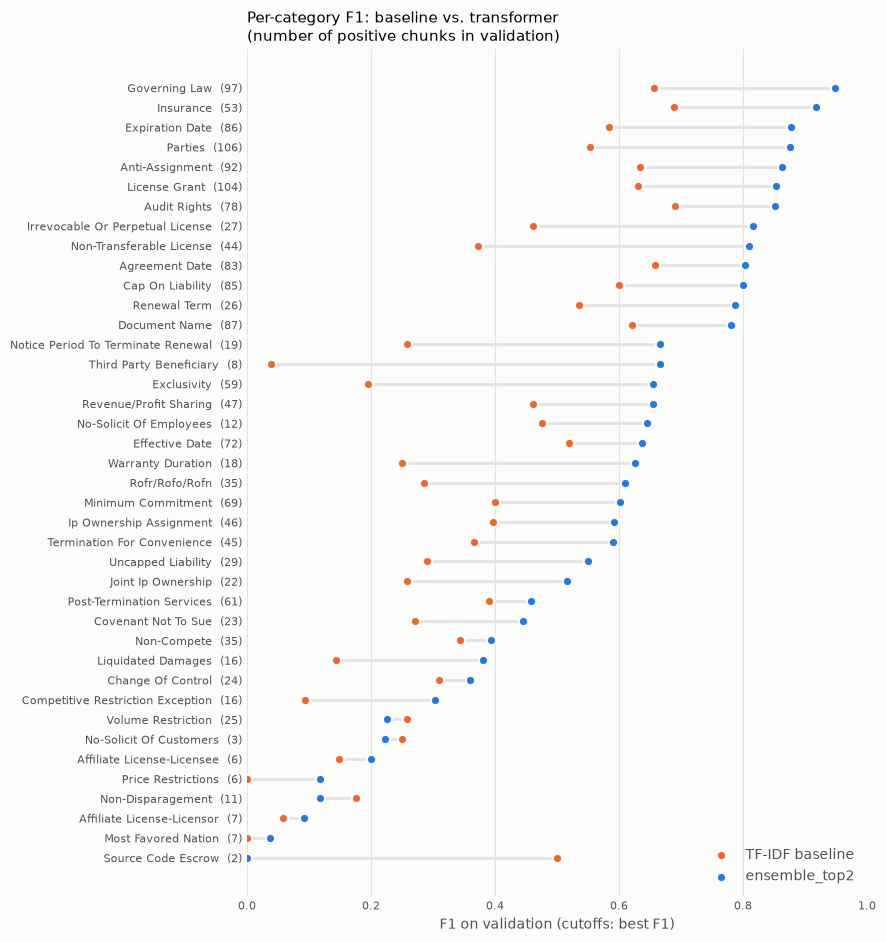

In [8]:
# dumbbell chart: one row per category, baseline dot -> transformer dot
TRANSFORMER_COLOR, BASELINE_COLOR = "#2a78d6", "#eb6834"   # categorical slots 1 and 2
TEXT_SECONDARY, GRID_COLOR, SURFACE = "#52514e", "#e4e3df", "#fcfcfb"

plot_df = present.sort_values("f1_transformer").reset_index(drop=True)
rows_y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(8, 11), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.hlines(rows_y, plot_df["f1_baseline"], plot_df["f1_transformer"], color=GRID_COLOR, linewidth=2, zorder=1)
ax.scatter(plot_df["f1_baseline"], rows_y, s=45, color=BASELINE_COLOR, edgecolors=SURFACE, linewidths=1.5,
           zorder=2, label="TF-IDF baseline")
ax.scatter(plot_df["f1_transformer"], rows_y, s=45, color=TRANSFORMER_COLOR, edgecolors=SURFACE, linewidths=1.5,
           zorder=3, label=f"{BEST_MODEL}")
ax.set_yticks(rows_y, labels=[f"{c}  ({n})" for c, n in zip(plot_df["category"], plot_df["n_positive"])])
ax.set_xlim(0, 1)
ax.set_xlabel(f"F1 on validation (cutoffs: {SELECTED_STRATEGY})", color=TEXT_SECONDARY)
ax.tick_params(colors=TEXT_SECONDARY, labelsize=8, length=0)
ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="lower right", frameon=False, labelcolor=TEXT_SECONDARY)
ax.set_title("Per-category F1: baseline vs. transformer\n(number of positive chunks in validation)",
             loc="left", fontsize=11)
fig.savefig(OUT_DIR / "baseline_vs_transformer_f1.png", dpi=150, bbox_inches="tight")
plt.show()

## 7B Error analysis on validation

Every (chunk, category) pair the best model gets wrong, with what's around it:

- **FN (missed clause)** -- how much of the evidence is actually inside the chunk. A clause that
  straddles a chunk boundary leaves only a sliver in one chunk, but that chunk is still labeled yes.
- **FP (false alarm)** -- whether the neighbouring chunk has that clause (the 187-token overlap
  shares text across the boundary), or the chunk has a *different* clause (category confusion).

In [9]:
val_df = parts["val"]
scores = probs[BEST_MODEL]["val"]
pred = (scores >= best_thr).astype(int)
y_val = y["val"]
cat_names = np.array(categories)

r, c = np.nonzero(pred != y_val)
errors = pd.DataFrame({
    "chunk_id": val_df["chunk_id"].to_numpy()[r],
    "contract_id": val_df["contract_id"].to_numpy()[r],
    "chunk_index": val_df["chunk_index"].to_numpy()[r],
    "category": cat_names[c],
    "error": np.where(y_val[r, c] == 1, "FN", "FP"),
    "prob": scores[r, c],
    "threshold": best_thr[c],
})

# per-category counts
per_cat = best_cat[["category", "n_positive", "precision", "recall", "f1"]].assign(
    tp=((pred == 1) & (y_val == 1)).sum(axis=0),
    fp=((pred == 1) & (y_val == 0)).sum(axis=0),
    fn=((pred == 0) & (y_val == 1)).sum(axis=0),
)
per_cat.to_csv(OUT_DIR / "val_errors_by_category.csv", index=False)
print(f"{(errors['error'] == 'FP').sum()} false positives, {(errors['error'] == 'FN').sum()} false negatives "
      f"out of {int(y_val.sum())} real positives\n")
print("categories with the most missed clauses:")
print(per_cat.sort_values("fn", ascending=False).head(12).round(2).to_string(index=False))

684 false positives, 511 false negatives out of 1691 real positives

categories with the most missed clauses:
                   category  n_positive  precision  recall   f1  tp  fp  fn
  Post-Termination Services          61       0.43    0.49 0.46  30  40  31
             Effective Date          72       0.70    0.58 0.64  42  18  30
           Cap On Liability          85       0.97    0.68 0.80  58   2  27
         Minimum Commitment          69       0.58    0.62 0.60  43  31  26
    Ip Ownership Assignment          46       0.84    0.46 0.59  21   4  25
                Non-Compete          35       0.52    0.31 0.39  11  10  24
              Document Name          87       0.83    0.74 0.78  64  13  23
              License Grant         104       0.94    0.78 0.85  81   5  23
                Exclusivity          59       0.67    0.64 0.66  38  19  21
             Agreement Date          83       0.85    0.76 0.80  63  11  20
Termination For Convenience          45       0.60    

### Missed clauses (FN): is the evidence actually in the chunk?

In [10]:
# how much of each positive's evidence sits inside the chunk (a chunk can hold several spans: keep the biggest)
ev = chunk_evidence_df.merge(table[["chunk_id", "chunk_start", "chunk_end"]], on="chunk_id")
ev["chars_in_chunk"] = (np.minimum(ev["annotation_end"], ev["chunk_end"])
                        - np.maximum(ev["annotation_start"], ev["chunk_start"]))
pos_evidence = ev.groupby(["chunk_id", "category"]).agg(
    fully_contained=("fully_contained", "any"),
    chars_in_chunk=("chars_in_chunk", "max"),
    evidence_text=("annotation_text", lambda s: " ||| ".join(s)),
).reset_index()

# recall for every real positive in validation, split by how much evidence the chunk holds
r, c = np.nonzero(y_val == 1)
positives = pd.DataFrame({
    "chunk_id": val_df["chunk_id"].to_numpy()[r],
    "category": cat_names[c],
    "found": pred[r, c] == 1,
}).merge(pos_evidence, on=["chunk_id", "category"], how="left")
assert positives["fully_contained"].notna().all(), "a positive label has no evidence row -- stale chunk_evidence_df?"

positives["evidence"] = np.where(positives["fully_contained"].astype(bool),
                                 "whole span in chunk", "only part of span in chunk")
positives["chars_bin"] = pd.cut(positives["chars_in_chunk"], [0, 50, 200, 500, np.inf],
                                labels=["< 50 chars", "50-200", "200-500", "500+"], include_lowest=True)

for col in ("evidence", "chars_bin"):
    summary = positives.groupby(col, observed=True)["found"].agg(positives="size", recall="mean")
    print(summary.round(2).to_string(), "\n")

                            positives  recall
evidence                                     
only part of span in chunk         36    0.39
whole span in chunk              1655    0.70 

            positives  recall
chars_bin                    
< 50 chars        314    0.71
50-200            356    0.65
200-500           721    0.72
500+              300    0.70 



### False alarms (FP): what's in or next to the chunk?

In [11]:
located = positives.join(val_df.set_index("chunk_id")[["contract_id", "chunk_index"]], on="chunk_id")
positive_keys = set(zip(located["contract_id"], located["chunk_index"], located["category"]))
true_categories = positives.groupby("chunk_id")["category"].apply(list).to_dict()

fp = errors[errors["error"] == "FP"].copy()
fp["neighbour_has_category"] = [
    (cid, idx - 1, cat) in positive_keys or (cid, idx + 1, cat) in positive_keys
    for cid, idx, cat in zip(fp["contract_id"], fp["chunk_index"], fp["category"])
]
fp["chunk_true_categories"] = fp["chunk_id"].map(lambda cid: ", ".join(true_categories.get(cid, [])))
fp["pattern"] = np.select(
    [fp["neighbour_has_category"], fp["chunk_true_categories"] != ""],
    ["next chunk has this clause (boundary)", "chunk has a different clause (confusion)"],
    default="no clause in or next to chunk",
)
print(fp["pattern"].value_counts().to_string(), "\n")

# which categories get mistaken for which
confusions = (fp[fp["pattern"] == "chunk has a different clause (confusion)"]
              .assign(true_category=lambda d: d["chunk_true_categories"].str.split(", "))
              .explode("true_category")
              .groupby(["category", "true_category"]).size().rename("n").sort_values(ascending=False))
print("most common confusions (predicted -> actually in the chunk):")
print(confusions.head(15).to_string(), "\n")

first_chunk = val_df["chunk_index"].to_numpy() == 0
for label, mask in (("first chunk of contract", first_chunk), ("all other chunks", ~first_chunk)):
    n = mask.sum()
    print(f"{label:>24}: {((pred == 1) & (y_val == 0))[mask].sum() / n:.2f} FP per chunk, "
          f"{((pred == 0) & (y_val == 1))[mask].sum() / n:.2f} FN per chunk ({n} chunks)")

pattern
chunk has a different clause (confusion)    433
no clause in or next to chunk               171
next chunk has this clause (boundary)        80 

most common confusions (predicted -> actually in the chunk):
category                    true_category                   
Affiliate License-Licensor  License Grant                       59
                            Non-Transferable License            33
Uncapped Liability          Cap On Liability                    24
Affiliate License-Licensor  Exclusivity                         21
                            Irrevocable Or Perpetual License    19
                            Ip Ownership Assignment             19
Affiliate License-Licensee  License Grant                       19
Affiliate License-Licensor  Joint Ip Ownership                  18
Volume Restriction          License Grant                       14
                            Minimum Commitment                  13
                            Exclusivity               

### Examples to read by hand

The 15 most confident false alarms and the 15 most confidently missed clauses, one per category
first so a single noisy category doesn't fill the list. Saved to CSV with an empty `notes` column
for writing down what went wrong (label noise? chunk boundary? genuinely hard?).

In [12]:
N_EXAMPLES = 15  # milestone 7B asks for at least 10 of each
chunk_text = val_df.set_index("chunk_id")["chunk_text"]


def pick_examples(df, ascending):
    """Most extreme by prob, one per category first, then the rest."""
    ordered = df.sort_values("prob", ascending=ascending)
    spread = ordered.drop_duplicates("category")
    return pd.concat([spread, ordered.drop(spread.index)]).head(N_EXAMPLES).reset_index(drop=True)


fn = errors[errors["error"] == "FN"].merge(pos_evidence, on=["chunk_id", "category"], how="left")
fn_examples = pick_examples(fn, ascending=True).assign(notes="")
fp_examples = pick_examples(fp, ascending=False).assign(notes="")
for df in (fn_examples, fp_examples):
    df["chunk_text"] = df["chunk_id"].map(chunk_text)

fp_examples.to_csv(OUT_DIR / "fp_examples.csv", index=False)
fn_examples.to_csv(OUT_DIR / "fn_examples.csv", index=False)
errors.to_csv(OUT_DIR / "val_errors.csv", index=False)


def show(df, kind):
    for i, row in df.iterrows():
        print(f"--- {kind} {i + 1}: {row['category']} | prob {row['prob']:.3f} (cutoff {row['threshold']:.2f}) "
              f"| {row['chunk_id']}")
        if kind == "FN":
            where = "whole span" if row["fully_contained"] else f"only {row['chars_in_chunk']:.0f} chars"
            print(f"evidence ({where} in chunk): {textwrap.shorten(row['evidence_text'], 400)}")
        else:
            print(f"pattern: {row['pattern']} | chunk is labeled: {row['chunk_true_categories'] or 'nothing'}")
            print(f"chunk text: {textwrap.shorten(row['chunk_text'], 400)}")
        print()


show(fn_examples, "FN")

--- FN 1: Irrevocable Or Perpetual License | prob 0.000 (cutoff 0.42) | AlliedEsportsEntertainmentInc_20190815_8-K_EX-10.19_11788293_EX-10.19_Content License Agreement__chunk14
evidence (whole span in chunk): Notwithstanding any termination of this Agreement, any Approved Content that includes Zynga's Licensed Property may remain in perpetuity in any media in which such Licensed Property was integrated into during the Term (e.g., televised WPT Tournaments or WPT Invitational Tournaments, social media posts, repurposed integrations for "best of" television programs) or for historical purposes [...]

--- FN 2: Ip Ownership Assignment | prob 0.000 (cutoff 0.48) | IMAGEWARESYSTEMSINC_12_20_1999-EX-10.22-MAINTENANCE AGREEMENT__chunk2
evidence (whole span in chunk): (c) give title to all modifications and improvements to the PSS Software which XIMAGE generally makes available to its other customers (at no additional Charge) under standard software maintenance agreements relating to the Softw

In [13]:
show(fp_examples, "FP")

--- FP 1: Anti-Assignment | prob 1.000 (cutoff 0.53) | ADUROBIOTECH,INC_06_02_2020-EX-10.7-CONSULTING AGREEMENT__chunk3
pattern: chunk has a different clause (confusion) | chunk is labeled: Governing Law
chunk text: 8. Representations. Consultant represents as follows: (a) Consultant is not subject to any other agreement that Consultant will violate by signing this Agreement; (b) Consultant has and shall continue to have the knowledge, experience, qualifications and required skill to perform, and shall perform, the Services in a professional manner; (c) Consultant to perform the Services in accordance [...]

--- FP 2: Audit Rights | prob 0.996 (cutoff 0.17) | UpjohnInc_20200121_10-12G_EX-2.6_11948692_EX-2.6_Manufacturing Agreement_ Supply Agreement__chunk33
pattern: no clause in or next to chunk | chunk is labeled: nothing
chunk text: Source: UPJOHN INC, 10-12G, 1/21/2020 3.4 Price Review and Audit Procedure. (a) Manufacturer shall maintain complete and accurate Records that fairly ref

--- FP 9: Minimum Commitment | prob 0.957 (cutoff 0.21) | GRIDIRONBIONUTRIENTS,INC_02_05_2020-EX-10.3-SUPPLY AGREEMENT__chunk0
pattern: chunk has a different clause (confusion) | chunk is labeled: Document Name, Parties
chunk text: EXHIBIT 10.3 SUPPLY AGREEMENT This Agreement ("the Agreement"), is made by and between EWSD 1, LLC, d/b/a/ SHI FARMS ("Shi Farms"), a Delaware limited liability company and Gridiron BioNutrients, Inc, a Nevada Corporation ("Gridiron") , each individually "a Party," and collectively, "the Parties." WHEREAS Shi Farms grows industrial hemp and wishes to sell hemp biomass ("Product"); and [...]

--- FP 10: License Grant | prob 0.951 (cutoff 0.62) | IbioInc_20200313_8-K_EX-10.1_12052678_EX-10.1_Development Agreement__chunk4
pattern: chunk has a different clause (confusion) | chunk is labeled: Joint Ip Ownership, Rofr/Rofo/Rofn
chunk text: Master Joint Development Agreement iBio CC-Pharming Source: IBIO, INC., 8-K, 3/13/2020 4.3 Each Party shall promptly provide t

## Findings (validation set, from the run on 2026-10-25)

- **Best model / cutoffs:** `ensemble_top2` = average of `modernbert_v2_biasinit` + `modernbert_v1_6ep`, with per-category best-F1 cutoffs. Picked on tune macro AP (0.590, vs 0.569 for the best single run).
- **Improvement experiments (8A):** ensembling the top two runs is the best change -- val macro F1 0.559 vs 0.536 for `v2_biasinit` alone with the same cutoffs. Per-category cutoffs raise macro F1 for every transformer run (e.g. v2: 0.506 -> 0.536) but *lower* micro F1 (0.700 -> 0.640): they trade precision for recall on the rare categories. Recall-weighted (x3) cutoffs reach ~0.83 micro recall at ~0.40 precision -- an option if the triage use case values coverage.
- **Baseline vs. transformer (7A):** macro F1 0.371 -> 0.559, micro F1 0.433 -> 0.664, macro AP 0.408 -> 0.593. The transformer wins in 36 of 40 categories; the 4 losses (Source Code Escrow, No-Solicit Of Customers, Non-Disparagement, Volume Restriction) all have 2-25 positives in validation, so they're noisy.
- **Missed clauses (511 FN):** evidence length doesn't matter (recall 0.65-0.72 in every length bin). Clauses cut by a chunk boundary are missed more often (recall 0.39 vs 0.70) but are only 36 of 1691 positives. Many of the most confident misses look like loose or questionable labels: "period." labeled Revenue/Profit Sharing, a reimbursement clause labeled Exclusivity, an injunction clause labeled Uncapped Liability, an unfilled template date labeled Effective Date.
- **False alarms (684 FP):** 63% are chunks that hold a *different* clause -- category confusion. Most of that is one category: **Affiliate License-Licensor** (7 val positives) fires on License Grant / Non-Transferable License / Exclusivity / IP chunks (~170 FPs). Other confusions: Uncapped Liability vs. Cap On Liability (24), Renewal Term vs. Expiration Date, Effective Date vs. Parties. 12% are next to a real clause (overlap at chunk boundaries). Some "no clause nearby" FPs look like real clauses missing a label (e.g. a "Choice of Law ... governed by the laws of Delaware" chunk predicted Governing Law at 0.995, labeled nothing) -- worth checking how CUAD annotates repeated clauses.
- **Position:** the first chunk of each contract has about twice the error rate (0.72 FP / 0.57 FN per chunk vs. 0.36 / 0.26), where Document Name, Parties, Agreement Date and Effective Date all sit together.
- **Next experiments:** (no GPU) don't tune cutoffs for categories with very few tune positives -- keep 0.5 or set a floor, which should cut the Affiliate License-Licensor false alarms; (GPU) `--bias-init` with 6 epochs, since both bias init and more epochs helped separately.